# Constants

In [47]:
app_heights = [50, 100, 150, 200, 250, 300, 350]

In [48]:
import pandas as pd

I_V = 0.83e-2            # cm^-2 s^-1 sr^-1 (Rossi 1948)
W, Lp = 20.0, 50.0       # paddle footprint in cm (ASSUMED 30 x 30 cm, confirm against the real paddles)
c = 29.9792458           # speed of light, cm/ns

# Zenith Angle Calculation

In [49]:
# Eq. (8): I(phi) = I_V cos^2(phi),  dN = I(phi) dOmega dA_perp dt
# Horizontal paddle: dA_perp = dA cos(phi)
#   single paddle, all directions: R = I_V * A * 2pi * int cos^3 sin dphi = (pi/2) I_V A
#   coincidence of paddles A (top) and B (bottom), separation h:
#     dOmega = dA_B cos(phi)/r^2,  cos(phi) = h/r
#     R = I_V * G,   G = int int cos^4(phi)/r^2 dA_A dA_B = int int h^4/r^6 dA_A dA_B
n = 100                                         # midpoints per axis (n^2 cells per paddle)

def mid(L, n):
    return (np.arange(n) + 0.5) * L / n - L / 2

x, y = np.meshgrid(mid(W, n), mid(Lp, n), indexing="ij")
x, y = x.ravel(), y.ravel()
dA = (W / n) * (Lp / n)
rho2 = (x[:, None] - x[None, :])**2 + (y[:, None] - y[None, :])**2   # horizontal offset^2

R_single = np.pi / 2 * I_V * W * Lp            # counts/s in one paddle, all directions

rows = []
for h in app_heights:
    r2 = rho2 + h**2
    cos_t = h / np.sqrt(r2)
    w = h**4 / r2**3                           # integrand of G
    G = w.sum() * dA**2                        # cm^2 sr
    R = I_V * G                                # coincidences / s
    L_mean = (w * h / cos_t).sum() / w.sum()   # flux-weighted slant path
    rows.append({
        "h (cm)": h,
        "theta_max (deg)": np.degrees(np.arctan(np.hypot(W, Lp) / h)),
        "<theta> (deg)": (w * np.degrees(np.arccos(cos_t))).sum() / w.sum(),
        "<L> (cm)": L_mean,
        "G (cm^2 sr)": G,
        "R_coinc (1/s)": R,
        "R_coinc (1/min)": R * 60,
        "R_coinc (1/hr)": R * 3600,
        "R_coinc/R_single": R / R_single,
        "<TOF> (ns)": L_mean / c,
    })

table = pd.DataFrame(rows).round(4)
print(f"Single-paddle rate, all directions: {R_single:.2f} /s  ({R_single*60:.0f} /min)")
table

Single-paddle rate, all directions: 13.04 /s  (782 /min)


,h (cm),theta_max (deg),<theta> (deg),<L> (cm),G (cm^2 sr),R_coinc (1/s),R_coinc (1/min),R_coinc (1/hr),R_coinc/R_single,<TOF> (ns)
0,50,47.1240,16.4731,52.9373,266.7966,2.2144,132.8647,7971.8823,0.1698,1.7658
1,100,28.3032,9.9721,102.0582,87.8676,0.7293,43.7580,2625.4827,0.0559,3.4043
2,150,19.7487,6.9851,151.4934,41.8117,0.3470,20.8222,1249.3326,0.0266,5.0533
3,200,15.0700,5.3391,201.1567,24.1367,0.2003,12.0201,721.2040,0.0154,6.7099
4,250,12.1561,4.3104,250.9397,15.6403,0.1298,7.7889,467.3318,0.0100,8.3704
5,300,10.1765,3.6102,300.7898,10.9360,0.0908,5.4461,326.7675,0.0070,10.0333
6,350,8.7470,3.1039,350.6805,8.0682,0.0670,4.0180,241.0777,0.0051,11.6974


# Apparatus Image


saved apparatus_sketch.pdf / .png


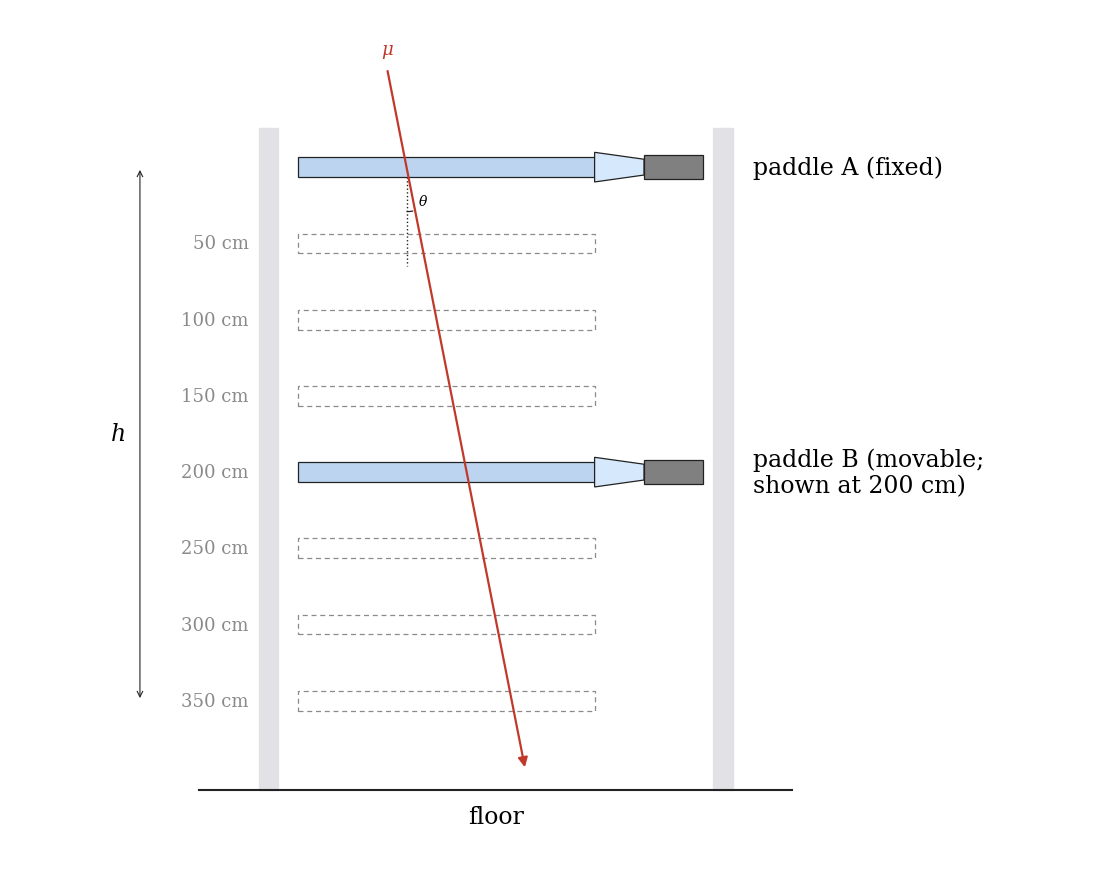

In [50]:
"""
Side view of the two-paddle time-of-flight apparatus, drawn with matplotlib.
Same geometry as Figure 1 of the TOF report (TikZ). Run: python3 apparatus_sketch.py
Outputs apparatus_sketch.pdf (vector, for LaTeX) and apparatus_sketch.png (for slides).
Coordinates are in arbitrary drawing units (not to scale), y up.
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, FancyBboxPatch, FancyArrowPatch, Arc

SCINT, GUIDE, PMT, STAND = "#bcd4f0", "#d6e8fb", "#808080", "#e1e1e6"
MUON, CABLE, GREY, INK = "#c0392b", "#8e2a1e", "#8a8a8a", "#222222"
plt.rcParams.update({"font.family": "serif", "font.size": 17, "mathtext.fontset": "dejavuserif"})

# full letter page, landscape (11 x 8.5 in); axes fill the whole figure with no margins
fig = plt.figure(figsize=(11, 8.5))
ax = fig.add_axes([0, 0, 1, 1])
ylo, yhi = -1.0, 7.6                     # content spans about -0.9 to 7.5 vertically
xc = 2.65; half = (yhi - ylo) * 11 / 8.5 / 2
ax.set_xlim(xc - half, xc + half); ax.set_ylim(ylo, yhi); ax.set_aspect("equal"); ax.axis("off")

# stand posts and floor
for x in (-0.4, 4.2):
    ax.add_patch(Rectangle((x, -0.3), 0.2, 6.7, color=STAND, zorder=0))
ax.plot([-1, 5], [-0.3, -0.3], color=INK, lw=1.5)
ax.text(2, -0.45, "floor", ha="center", va="top")

def paddle(y, dashed=False):
    """Scintillator bar + light guide + PMT, centred on height y."""
    if dashed:
        ax.add_patch(Rectangle((0, y - 0.1), 3.0, 0.2, fill=False, ls=(0, (4, 3)), ec=GREY, lw=0.9))
        return
    ax.add_patch(Rectangle((0, y - 0.1), 3.0, 0.2, fc=SCINT, ec=INK, lw=0.9, zorder=2))
    ax.add_patch(Polygon([(3.0, y - 0.15), (3.5, y - 0.08), (3.5, y + 0.08), (3.0, y + 0.15)],
                         fc=GUIDE, ec=INK, lw=0.9, zorder=2))
    ax.add_patch(Rectangle((3.5, y - 0.12), 0.6, 0.24, fc=PMT, ec=INK, lw=0.9, zorder=2))

# fixed top paddle A, all positions of B in app_heights
paddle(6.0)

# B positions drawn to scale: y = 6.0 - h * (6.0 - 0.6) / max(app_heights), so the lowest height sits at y = 0.6
y_of = lambda h: 6.0 - h * (6.0 - 0.6) / max(app_heights)
SHOWN = 200                                  # height at which B is drawn solid
for h in app_heights:
    y = y_of(h)
    if h != SHOWN:
        paddle(y, dashed=True)
    ax.text(-0.5, y, f"{h} cm", ha="right", va="center", color=GREY, fontsize=13)
paddle(y_of(SHOWN))
ax.text(4.6, 6.0, "paddle A (fixed)", ha="left", va="center")
ax.text(4.6, y_of(SHOWN), f"paddle B (movable;\nshown at {SHOWN} cm)", ha="left", va="center")

# separation arrow
ax.add_patch(FancyArrowPatch((-1.6, 6.0), (-1.6, y_of(max(app_heights))), arrowstyle="<->", mutation_scale=10, color=INK, lw=0.8))
ax.text(-1.75, 3.3, "$h$", ha="right", va="center")

# muon track, zenith angle and slant path
x0, y0, x1, y1 = 0.9, 7.0, 2.3, -0.1
ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=14, color=MUON, lw=1.6, zorder=3))
ax.text(x0, y0 + 0.08, r"$\mu$", color=MUON, ha="center", va="bottom", fontsize=13)
xa = x0 + (y0 - 6.0) * (x1 - x0) / (y0 - y1)          # where the track crosses paddle A
ax.plot([xa, xa], [5.9, 5.0], ls=":", color=INK, lw=1)
theta = np.degrees(np.arctan((x1 - x0) / (y0 - y1)))
ax.add_patch(Arc((xa, 5.9), 0.7, 0.7, theta1=-90, theta2=-90 + theta, color=INK, lw=0.9))
ax.text(xa + 0.12, 5.62, r"$\theta$", fontsize=10)


fig.savefig("apparatus_sketch.pdf")
fig.savefig("apparatus_sketch.png", dpi=200)
print("saved apparatus_sketch.pdf / .png")


# Process Diagram

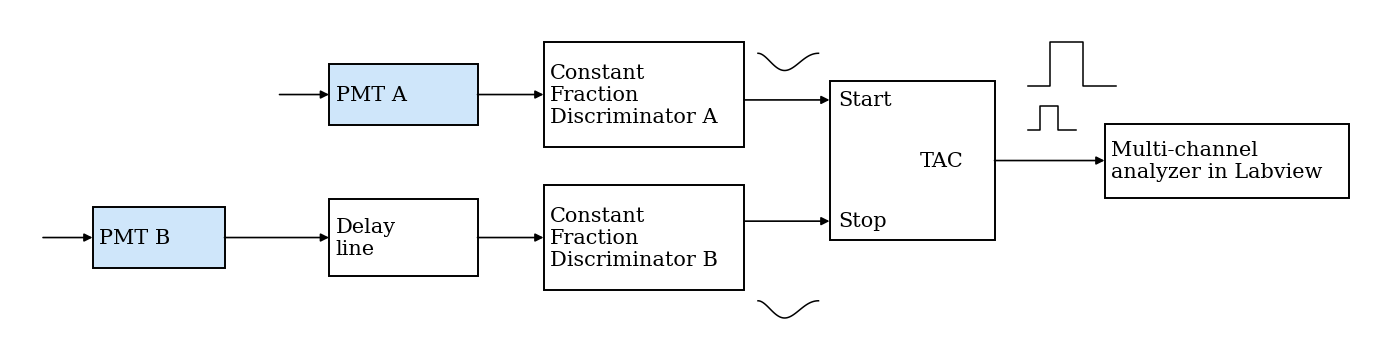

In [ ]:
# Block process diagram. Edit BLOCKS / ARROWS / PULSES below; add a row to add a block.
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# name: (x, y, width, height, label, inner label shown top-centre-left, optional)
# (x, y) is the block's lower-left corner; units are arbitrary drawing units.
BLOCKS = {
    "cfd1": (0.0, 2.6, 3.3, 1.9, "Constant\nFraction\nDiscriminator A"),
    "cfd2": (0.0, 0.0, 3.3, 1.9, "Constant\nFraction\nDiscriminator B"),
    "delay": (-3.9, 0.25, 2.7, 1.4, "Delay\nline (10-20ns)"),
    "pmtA": (-3.9, 3.0, 2.7, 1.1, "PMT A"),
    "pmtB": (-8.2, 0.4, 2.4, 1.1, "PMT B"),
    "tac":  (5.2, 0.9, 3.0, 2.9, "TAC"),
    "mca":  (10.2, 1.7, 3.2, 1.3, "Multi-channel\nanalyzer in Labview"),
}

# Fill colour per block (default white)
COLORS = {"pmtA": "#cfe6fa", "pmtB": "#cfe6fa"}

# (from, to, from-side, to-side, port label drawn inside the destination block)
# sides: "l", "r", "t", "b"; the arrow attaches at the middle of that side,
# or at a fraction along it if you give a number: ("r", 0.5);
# "match" on the source side makes the arrow horizontal (level with the destination point)
ARROWS = [
    ("cfd1", "tac", ("r", "match"), ("l", 0.88), "Start"),
    ("cfd2", "tac", ("r", "match"), ("l", 0.12), "Stop"),
    ("pmtA", "cfd1", ("r", "match"), ("l", 0.5), ""),
    ("pmtB", "delay", ("r", "match"), ("l", 0.5), ""),
    ("delay", "cfd2", ("r", 0.5), ("l", 0.5), ""),
    ("tac",  "mca", ("r", 0.5), ("l", 0.50), ""),
    # ("in", "cfd1", ...) for an input arrow: add a block "in" or use INPUTS below
]

# Short arrows coming in from the left with no source block: (block, fraction up the left side, label)
INPUTS = [("pmtA", 0.5, ""), ("pmtB", 0.5, "")]

# Little waveform glyphs: (kind, x, y, scale)   kinds: "neg", "pos" (smooth dip / bump),
# "square" (logic pulse), "step" (rising edge)
PULSES = [
    ("neg", 3.9, 4.3, 1.0), ("neg", 3.9, -0.2, 1.0),
    ("square", 8.8, 3.7, 1.0), ("square", 8.8, 2.9, 0.55),
]

FONT = 15
fig = plt.figure(figsize=(11, 6))
ax = fig.add_axes([0, 0, 1, 1])                 # fixed scale so text can be measured; saved with a tight bbox
ax.set_xlim(-5, 15); ax.set_ylim(2.2 - 20 * 6 / 11 / 2, 2.2 + 20 * 6 / 11 / 2)
ax.set_aspect("equal"); ax.axis("off")

# Auto-fit: grow any block (except the centre-labelled "tac") so its text fits with some padding.
PAD = 0.3
fig.canvas.draw()
for name, (x, y, w, h, label) in list(BLOCKS.items()):
    if name == "tac":
        continue
    t = ax.text(0, 0, label, fontsize=FONT)
    bb = t.get_window_extent(fig.canvas.get_renderer()).transformed(ax.transData.inverted())
    t.remove()
    nw, nh = max(w, bb.width + 2 * PAD), max(h, bb.height + 2 * PAD)
    BLOCKS[name] = (x, y - (nh - h) / 2, nw, nh, label)      # grow height about the block's centre

def side_pt(b, side, f=0.5):
    x, y, w, h = BLOCKS[b][:4]
    return {"l": (x, y + f * h), "r": (x + w, y + f * h),
            "b": (x + f * w, y), "t": (x + f * w, y + h)}[side]

for name, (x, y, w, h, label) in BLOCKS.items():
    ax.add_patch(Rectangle((x, y), w, h, fc=COLORS.get(name, "white"), ec="black", lw=1.4))
    if name == "tac":                                    # centre label, as in the reference
        ax.text(x + 0.55 * w, y + 0.5 * h, label, ha="left", va="center", fontsize=FONT)
    else:
        ax.text(x + 0.12, y + h / 2, label, ha="left", va="center", fontsize=FONT)

def arrow(p, q):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=12, color="black", lw=1.2, shrinkA=0, shrinkB=0))

for src, dst, (ss, sf), (ds, df), port in ARROWS:
    q = side_pt(dst, ds, df)
    if sf == "match":                                   # horizontal arrow: source point level with destination
        bx, by, bw, bh = BLOCKS[src][:4]
        sf = min(max((q[1] - by) / bh, 0.05), 0.95)
    arrow(side_pt(src, ss, sf), q)
    if port:
        px, py = side_pt(dst, ds, df)
        ax.text(px + 0.15, py, port, ha="left", va="center", fontsize=FONT)

for b, f, label in INPUTS:
    x, y = side_pt(b, "l", f)
    arrow((x - 0.9, y), (x, y))
    if label:
        ax.text(x - 0.95, y, label, ha="right", va="center", fontsize=FONT)

def pulse(kind, x, y, s):
    import numpy as np
    if kind in ("neg", "pos"):
        t = np.linspace(0, 1, 60); sign = -1 if kind == "neg" else 1
        ax.plot(x + 1.1 * s * t, y + sign * 0.55 * s * np.sin(np.pi * t) ** 2 * np.exp(-1.2 * t), color="black", lw=1.1)
    elif kind == "square":
        ax.plot([x, x + 0.4 * s, x + 0.4 * s, x + 1.0 * s, x + 1.0 * s, x + 1.6 * s],
                [y, y, y + 0.8 * s, y + 0.8 * s, y, y], color="black", lw=1.1)
    elif kind == "step":
        ax.plot([x, x + 0.6 * s, x + 0.6 * s, x + 1.2 * s], [y, y, y + 0.8 * s, y + 0.8 * s], color="black", lw=1.1)

for p in PULSES:
    pulse(*p)

# crop the canvas to the drawing (blocks, arrows, pulses) plus a margin
bb, m = ax.dataLim, 0.6
fig.set_size_inches(0.55 * (bb.width + 2 * m), 0.55 * (bb.height + 2 * m))   # keep 0.55 in/unit so text still fits
ax.set_xlim(bb.x0 - m, bb.x1 + m); ax.set_ylim(bb.y0 - m, bb.y1 + m)
fig.savefig("process_diagram.pdf", bbox_inches="tight")
fig.savefig("process_diagram.png", dpi=200, bbox_inches="tight")
plt.show()